# End-to-End Customer Churn Prediction System

## Project Overview

Customer churn means customers leaving a company or cancelling its services.

The purpose of this project is to develop a Machine Learning system that predicts whether a telecom customer is likely to leave the company.

## Project Objectives

1. Understand customer data.
2. Clean and preprocess the dataset.
3. Perform Exploratory Data Analysis (EDA).
4. Train a Random Forest classification model.
5. Evaluate model performance.
6. Identify important features affecting customer churn.
7. Save the trained Machine Learning model.
8. Build an interactive Streamlit application.

## Machine Learning Algorithm

Random Forest Classifier

## Dataset

IBM Telco Customer Churn Dataset

In [1]:
%pip install numpy

  Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp314-cp314-win_amd64.whl (12.7 MB)
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install pandas matplotlib seaborn

  Using cached pandas-3.1.1-cp314-cp314-win_amd64.whl.metadata (16 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached pandas-3.1.1-cp314-cp314-win_amd64.whl (10.9 MB)
Using cached matplotlib-3.11.2-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.4.0-cp314-cp314-win_amd64.whl (240 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp314-cp314-win_amd64.whl (2.

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl (8.4 MB)
Using cached narwhals-2.28.0-py3-none-any.whl (490 kB)
Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl (37.4 MB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)

   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ----------------------------- 1/4 [scipy]
   ---------- ------------


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Project Directory Setup

We will create separate folders for:

- Data: Stores the customer dataset.
- Models: Stores the trained Machine Learning model.
- Images: Stores graphs and visualizations.

This makes our project organized and easy to manage.

In [5]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
IMAGE_DIR = PROJECT_DIR / "images"

DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)
IMAGE_DIR.mkdir(exist_ok=True)

print("Project directories created successfully!")

print("Project location:", PROJECT_DIR)
print("Data folder:", DATA_DIR)
print("Models folder:", MODEL_DIR)
print("Images folder:", IMAGE_DIR)

Project directories created successfully!
Project location: c:\Users\dell\Desktop\Customer-Churn-Prediction
Data folder: c:\Users\dell\Desktop\Customer-Churn-Prediction\data
Models folder: c:\Users\dell\Desktop\Customer-Churn-Prediction\models
Images folder: c:\Users\dell\Desktop\Customer-Churn-Prediction\images


## 2. Dataset Acquisition

We will use the IBM Telco Customer Churn dataset.

The dataset contains information about 7,043 telecom customers.

Each row represents one customer.

The dataset includes:

- Customer information
- Contract information
- Internet services
- Monthly charges
- Total charges
- Customer churn status

Our target column is Churn.

Yes means the customer left the company.

No means the customer stayed with the company.

In [6]:
DATA_URL = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/"
    "Telco-Customer-Churn.csv"
)

DATA_PATH = DATA_DIR / "customer_churn.csv"

if not DATA_PATH.exists():
    df = pd.read_csv(DATA_URL)
    df.to_csv(DATA_PATH, index=False)
    print("Dataset downloaded successfully!")

else:
    df = pd.read_csv(DATA_PATH)
    print("Existing dataset loaded successfully!")

print("Dataset location:", DATA_PATH)
print("Dataset shape:", df.shape)

Dataset downloaded successfully!
Dataset location: c:\Users\dell\Desktop\Customer-Churn-Prediction\data\customer_churn.csv
Dataset shape: (7043, 21)


## 3. Understanding the Dataset

Before training our Machine Learning model, we need to understand our data.

We will:

1. Display the first five records.
2. Check the number of rows and columns.
3. Check column names.
4. Check data types.
5. Calculate basic statistical information.

In [7]:
print("First five records:")
display(df.head())

First five records:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape:
(7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    


In [9]:
print("Statistical Summary:")

display(df.describe(include="all").T)

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Data Cleaning

Data cleaning means fixing problems in our dataset before using it.

We will check:

1. Missing values.
2. Duplicate records.
3. Incorrect data types.
4. Unnecessary columns.

Important:

The TotalCharges column is stored as text in the original dataset.

We need to convert it into a numeric column.

Some customers have blank TotalCharges values. We will convert these blanks into missing values and fill them with zero because these customers have zero months of tenure.

In [10]:
print("Missing Values Before Cleaning:")

print(df.isnull().sum())

Missing Values Before Cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [11]:
print("Duplicate Rows:")

print(df.duplicated().sum())

print("\nDuplicate Customer IDs:")

print(df["customerID"].duplicated().sum())

Duplicate Rows:
0

Duplicate Customer IDs:
0


In [12]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Convert TotalCharges into numeric values
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"],
    errors="coerce"
)

# Fill missing TotalCharges with zero
df_clean["TotalCharges"] = df_clean["TotalCharges"].fillna(0)

# Remove unnecessary customer ID column
df_clean = df_clean.drop(columns=["customerID"])

print("Data cleaning completed!")

print("\nMissing Values After Cleaning:")

print(df_clean.isnull().sum().sum())

print("\nCleaned Dataset Shape:")

print(df_clean.shape)

Data cleaning completed!

Missing Values After Cleaning:
0

Cleaned Dataset Shape:
(7043, 20)


## 5. Target Variable Analysis

Our target variable is Churn.

It tells us whether a customer left the company.

We will convert the target into numerical values:

- Yes = 1
- No = 0

Machine Learning classification models need a numerical target for training.

In [13]:
df_clean["Churn"] = df_clean["Churn"].map({
    "Yes": 1,
    "No": 0
})

print("Target variable converted successfully!")

display(df_clean["Churn"].value_counts())

Target variable converted successfully!


Churn
0    5174
1    1869
Name: count, dtype: int64

## 6. Exploratory Data Analysis (EDA)

EDA means exploring our data using numbers, tables and graphs.

We want to understand:

- How many customers leave?
- How many customers stay?
- Which contracts have more churn?
- How does customer tenure affect churn?
- How do monthly charges relate to churn?

These visualizations help us understand customer behavior.

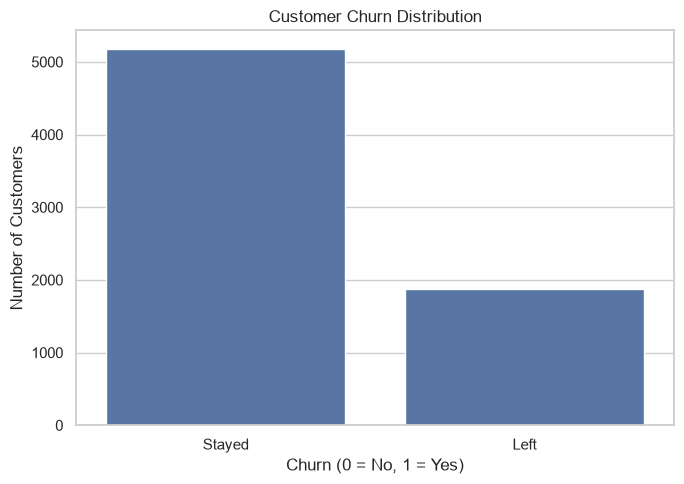

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_clean,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.xticks([0, 1], ["Stayed", "Left"])

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "churn_distribution.png",
    dpi=300
)

plt.show()

In [15]:
churn_percentage = (
    df_clean["Churn"]
    .value_counts(normalize=True) * 100
)

print("Customer Churn Percentage:")

print(churn_percentage)

print("\nChurned Customers:",
      (df_clean["Churn"] == 1).sum())

print("Customers Who Stayed:",
      (df_clean["Churn"] == 0).sum())

Customer Churn Percentage:
Churn
0    73.463013
1    26.536987
Name: proportion, dtype: float64

Churned Customers: 1869
Customers Who Stayed: 5174


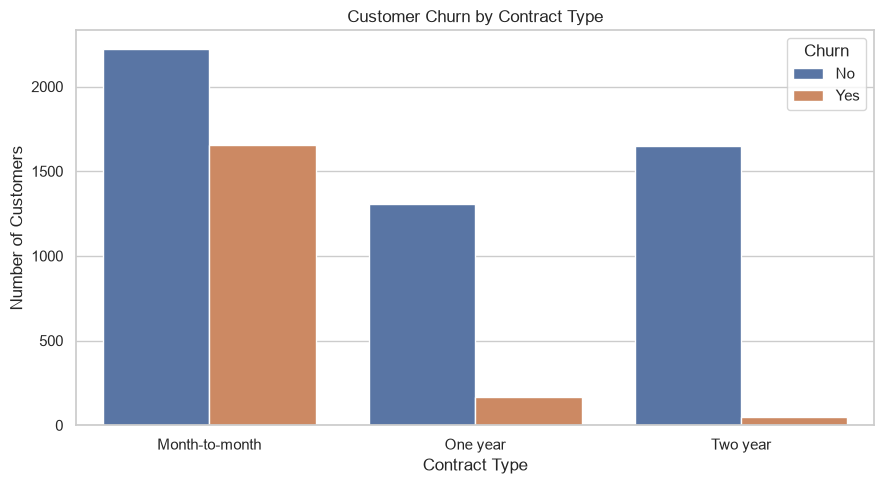

In [16]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "contract_churn.png",
    dpi=300
)

plt.show()

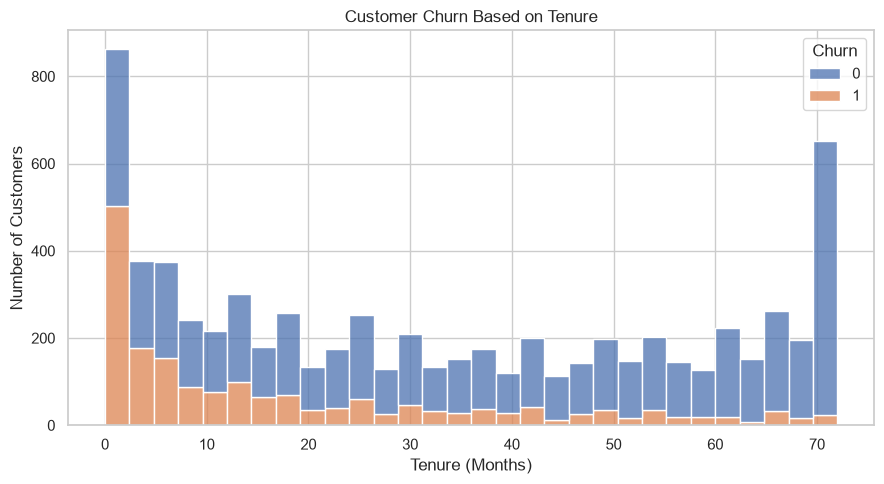

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack"
)

plt.title("Customer Churn Based on Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "tenure_churn.png",
    dpi=300
)

plt.show()

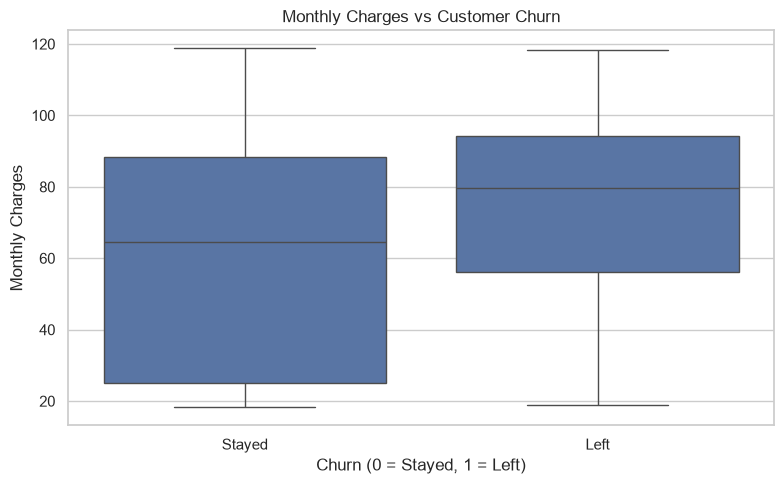

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Monthly Charges")

plt.xticks([0, 1], ["Stayed", "Left"])

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "monthly_charges_churn.png",
    dpi=300
)

plt.show()

## 7. Data Preprocessing

Machine Learning algorithms cannot directly understand text categories.

For example:

- Gender: Male / Female
- Contract: Month-to-month / One year / Two year
- Internet Service: DSL / Fiber optic / No

We will use One-Hot Encoding to convert these categories into numerical values.

We will also:

1. Separate input features (X).
2. Separate target variable (y).
3. Split the dataset into training and testing data.

Training data teaches the model.

Testing data checks how well the model performs on unseen customers.

We will use an 80:20 train-test split.

In [19]:
X = df_clean.drop(columns=["Churn"])

y = df_clean["Churn"]

print("Input Features Shape:", X.shape)

print("Target Variable Shape:", y.shape)

print("\nInput Features:")

print(X.columns.tolist())

Input Features Shape: (7043, 19)
Target Variable Shape: (7043,)

Input Features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [20]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")

print(numerical_features)

print("\nCategorical Features:")

print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

print("\nTraining and testing split completed!")

Training Data: (5634, 19)
Testing Data: (1409, 19)

Training and testing split completed!


## 8. Build the Preprocessing Pipeline

We will create a preprocessing pipeline.

It will:

1. Fill missing numerical values using the median.
2. Fill missing categorical values using the most frequent value.
3. Convert categorical columns into numerical columns using One-Hot Encoding.

We fit the preprocessing steps only on training data to prevent data leakage.

Data leakage means allowing information from testing data to influence model training.

In [22]:
# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

# Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 9. Build the Random Forest Classifier

Random Forest is a Machine Learning algorithm.

It creates multiple decision trees and combines their predictions to make a final prediction.

For this project:

- Input: Customer information.
- Output: Churn or No Churn.

We will use Random Forest as our main classification algorithm.

We will also use class_weight="balanced" to help the model pay attention to the less frequent churn class.

In [23]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [24]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", random_forest)
    ]
)

print("Complete Machine Learning pipeline created!")

Complete Machine Learning pipeline created!


## 10. Model Training

Now we will train our Random Forest model.

During training, the model studies customer information and learns patterns associated with customers who leave or stay.

The model will learn from X_train and y_train.

In [25]:
model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


## 11. Make Predictions

After training, we will test our model using unseen customer records.

The model will predict:

- 0 = Customer stays.
- 1 = Customer leaves.

We will also calculate churn probabilities.

In [26]:
y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

print("Predictions completed successfully!")

print("\nFirst 10 Predictions:")

print(y_pred[:10])

Predictions completed successfully!

First 10 Predictions:
[0 1 0 0 0 1 1 0 0 1]


## 12. Model Evaluation

We need to check how well our model performs.

We will calculate:

1. Accuracy: Percentage of all predictions that are correct.
2. Precision: Out of customers predicted to leave, how many actually left?
3. Recall: Out of customers who actually left, how many did the model identify?
4. F1-score: Balance between precision and recall.
5. ROC-AUC: Measures how well the model separates the two classes.

Recall is particularly important in churn prediction because we want to identify as many customers who may leave as possible.

In [28]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print("RANDOM FOREST MODEL PERFORMANCE")

print(f"Accuracy:  {accuracy:.4f}")

print(f"Precision: {precision:.4f}")

print(f"Recall:    {recall:.4f}")

print(f"F1 Score:  {f1:.4f}")

print(f"ROC-AUC:   {roc_auc:.4f}")

RANDOM FOREST MODEL PERFORMANCE
Accuracy:  0.7516
Precision: 0.5237
Recall:    0.7086
F1 Score:  0.6023
ROC-AUC:   0.8343


In [29]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Stayed", "Left"],
        zero_division=0
    )
)

Classification Report:

              precision    recall  f1-score   support

      Stayed       0.88      0.77      0.82      1035
        Left       0.52      0.71      0.60       374

    accuracy                           0.75      1409
   macro avg       0.70      0.74      0.71      1409
weighted avg       0.78      0.75      0.76      1409



## 13. Confusion Matrix

A confusion matrix shows the correct and incorrect predictions of our model.

It contains four values:

- True Negative: Correctly predicted a customer would stay.
- True Positive: Correctly predicted a customer would leave.
- False Positive: Predicted a customer would leave, but they stayed.
- False Negative: Predicted a customer would stay, but they left.

We will visualize these results using a confusion matrix.

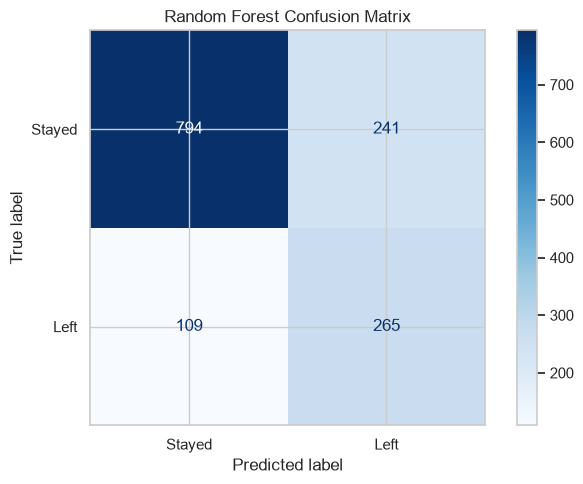

In [30]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Left"]
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    cmap="Blues",
    ax=ax,
    values_format="d"
)

plt.title("Random Forest Confusion Matrix")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "confusion_matrix.png",
    dpi=300
)

plt.show()

## 14. ROC Curve

The ROC curve shows how well our model separates customers who leave from customers who stay.

A higher ROC-AUC score generally means better separation between the two classes.

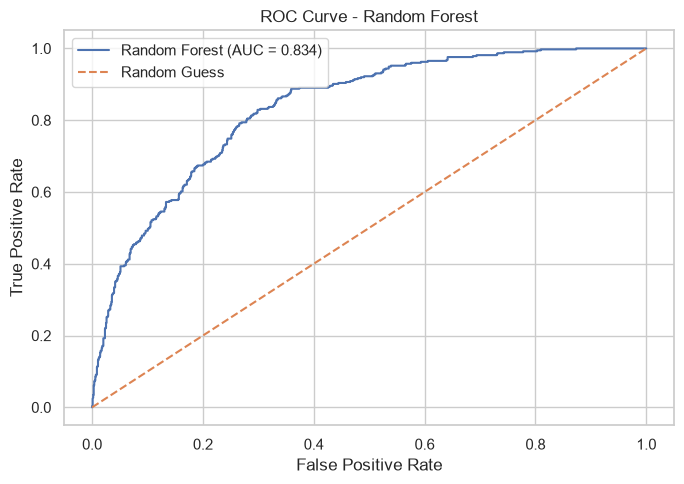

In [31]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Guess"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Random Forest")

plt.legend()

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "roc_curve.png",
    dpi=300
)

plt.show()

## 15. Feature Importance Analysis

Feature importance helps us understand which customer information is most useful to our model.

For example:

- Contract type
- Customer tenure
- Monthly charges
- Internet service
- Payment method

We will extract feature importance from our trained Random Forest model.

This helps the company understand which factors are associated with customer churn predictions.

In [32]:
# Get the trained preprocessing component
trained_preprocessor = model.named_steps["preprocessor"]

# Get the trained Random Forest classifier
trained_classifier = model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = trained_preprocessor.get_feature_names_out()

# Get feature importance values
importance_values = trained_classifier.feature_importances_

# Create a DataFrame
feature_data = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort features by importance
feature_data = feature_data.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")

display(feature_data.head(15))

Top 15 Important Features:


,Feature,Importance
1,num__tenure,0.127345
3,num__TotalCharges,0.119391
36,cat__Contract_Month-to-month,0.097724
2,num__MonthlyCharges,0.093349
38,cat__Contract_Two year,0.050143
18,cat__OnlineSecurity_No,0.050141
27,cat__TechSupport_No,0.045605
16,cat__InternetService_Fiber optic,0.038382
43,cat__PaymentMethod_Electronic check,0.033712
21,cat__OnlineBackup_No,0.018700


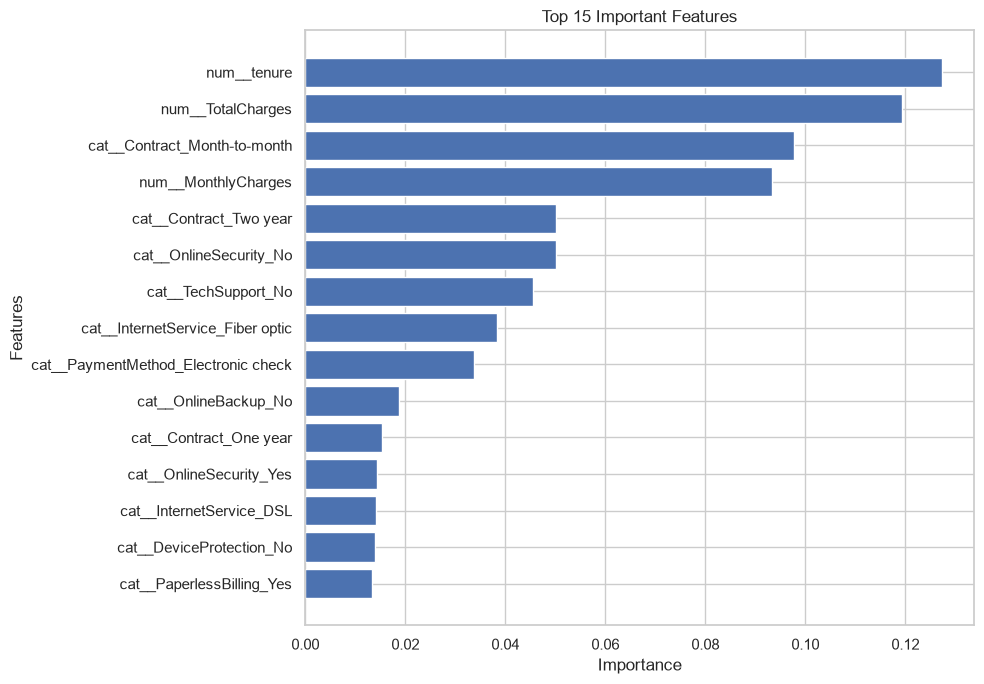

In [33]:
top_features = feature_data.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Important Features")

plt.xlabel("Importance")

plt.ylabel("Features")

plt.tight_layout()

plt.savefig(
    IMAGE_DIR / "feature_importance.png",
    dpi=300
)

plt.show()

## 16. Save the Trained Model

Training a model can take time.

We will save the complete Machine Learning pipeline using Joblib.

This saved pipeline includes:

- Data preprocessing
- One-Hot Encoding
- Random Forest classifier

We can load this saved model later inside our Streamlit application.

We do not need to train the model again whenever the application runs.

In [34]:
MODEL_PATH = MODEL_DIR / "churn_prediction_model.joblib"

joblib.dump(model, MODEL_PATH)

print("Model saved successfully!")

print("Model location:", MODEL_PATH)

Model saved successfully!
Model location: c:\Users\dell\Desktop\Customer-Churn-Prediction\models\churn_prediction_model.joblib


## 17. Load and Test the Saved Model

Now we will load our saved model.

We will use it to make predictions on testing data.

This verifies that our saved model can be used independently of the training process.

In [36]:
loaded_model = joblib.load(MODEL_PATH)

saved_predictions = loaded_model.predict(X_test)

print("Saved model loaded successfully!")

print("\nFirst 10 Predictions:")

print(saved_predictions[:10])

Saved model loaded successfully!

First 10 Predictions:
[0 1 0 0 0 1 1 0 0 1]


In [37]:
prediction_results = X_test.copy()

prediction_results["Actual_Churn"] = y_test.values

prediction_results["Predicted_Churn"] = saved_predictions

prediction_results["Churn_Probability"] = (
    loaded_model.predict_proba(X_test)[:, 1]
)

prediction_path = DATA_DIR / "test_predictions.csv"

prediction_results.to_csv(
    prediction_path,
    index=False
)

print("Test predictions saved successfully!")

print("File location:", prediction_path)

display(prediction_results.head())

Test predictions saved successfully!
File location: c:\Users\dell\Desktop\Customer-Churn-Prediction\data\test_predictions.csv


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Actual_Churn,Predicted_Churn,Churn_Probability
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20,0,0,0.003465
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,...,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55,0,1,0.840872
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,...,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20,0,0,0.099475
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,No,Electronic check,78.20,1468.75,0,0,0.490738
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,...,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35,0,0,0.050093


# 18. Project Conclusion

In this project, we developed an End-to-End Customer Churn Prediction System using Python and Machine Learning.

We completed the following tasks:

1. Downloaded the IBM Telco Customer Churn dataset.
2. Explored and understood customer information.
3. Cleaned missing and incorrect values.
4. Performed Exploratory Data Analysis.
5. Prepared numerical and categorical features.
6. Trained a Random Forest classification model.
7. Evaluated the model using classification metrics.
8. Created a confusion matrix and ROC curve.
9. Identified important customer features.
10. Saved the trained Machine Learning pipeline.
11. Prepared the model for deployment using Streamlit.

The system can help telecom companies identify customers who may be at risk of leaving and prioritize customer retention efforts.

## Important Note

The model provides predictions, not guarantees. Its performance should be tested and monitored before real business use.